# RMSProp/Momentum/Adam

## Momentum

Idea appeared as an interesting interpretation of physical phenomenon - impulse, in machine learning  
**Boris Polyak's idea**. As an optimization algorithm was made by **David Everett Rumelhart, Geoffrey Everest Hinton and Ronald James Williams**.

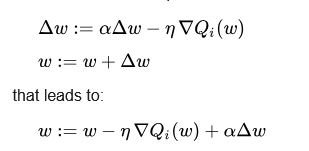


**Loss for each gradient descent in this work**  
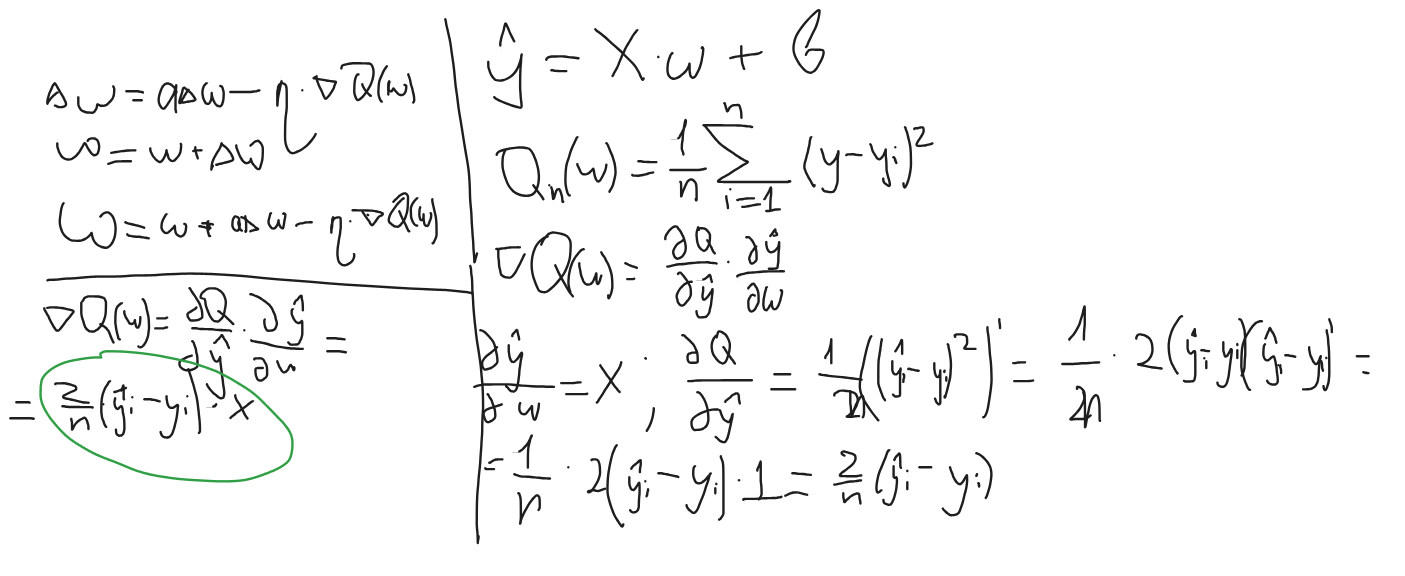
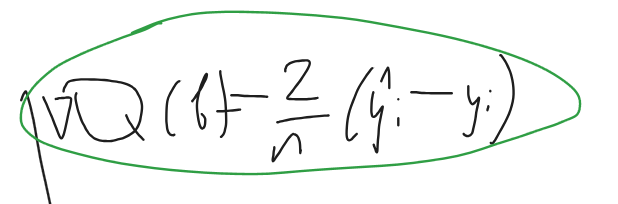

In [29]:
import random

random.seed(42)

class LinearMomentum:
    def __init__(self, eta: float = 0.01, epochs: int = 100, batch_size: int = 64, decay_factor: float = 0.9):
        self.eta = eta
        self.epochs = epochs
        self.batch_size = batch_size
        self.decay_factor = decay_factor 
        self.weights = None
        self.memory_w = None
        self.memory_b = 0.0
        self.bias = 0.0
        self.loss_history = []
        
    def fit(self, X, y):
        n_samples = len(X)
        n_features = len(X[0])
        
        self.weights = [0.0] * n_features
        self.bias = 0.0
        self.memory_w = [0.0] * n_features
        self.memory_b = 0.0
        self.loss_history = []
        
        for epoch in range(self.epochs):
            queue = list(range(n_samples))
            random.shuffle(queue)
            
            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = min(start_idx + self.batch_size, n_samples)
                batch = queue[start_idx:end_idx]
                curr_batch_size = len(batch)
                
                d_theta = [0.0] * n_features
                d_bias = 0.0
                
                error = 0
                for i in batch:
                    
                    pred = sum(X[i][j] * self.weights[j] for j in range(n_features)) + self.bias
                    err = pred - y[i]
                    
                    d_bias += err
                    for j in range(n_features):
                        d_theta[j] += err * X[i][j]
                    error += err**2
                self.loss_history.append(error/curr_batch_size)
                
                grad_b = 2*d_bias / curr_batch_size
                
                self.memory_b = self.decay_factor * self.memory_b + self.eta * grad_b
                self.bias -= self.memory_b
                
                for j in range(n_features):
                    grad_w_j = d_theta[j] / curr_batch_size
                    
                    self.memory_w[j] = self.decay_factor * self.memory_w[j] + self.eta * grad_w_j
                    self.weights[j] -= self.memory_w[j]
                    
            
            
    def predict(self, X):
        if self.weights is None:
            raise ValueError('You have to fit model before predict!')
        
        predictions = []
        for i in range(len(X)):
            pred = sum(X[i][j] * self.weights[j] for j in range(len(X[0]))) + self.bias
            predictions.append(pred)
            
        return predictions

In [30]:
def MSE(y_true, y_pred):
    if len(y_true) != len(y_pred):
        return
    
    mse_sum = 0
    for i in range(len(y_true)):
        mse_sum += (y_true[i] - y_pred[i])**2
        
    return mse_sum/len(y_true)

Let test algorithm on regression with some noize  

In [31]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
import time

X, y = make_regression(1000, 10, noise=5)
X_train, X_test, y_train, y_test = train_test_split(X, y)

Momentum = LinearMomentum()
start_moment = time.time()
Momentum.fit(X_train, y_train)
end_moment = time.time()
pred_momentum = Momentum.predict(X_test)
mse_momentum = MSE(pred_momentum, y_test)

print('MSE:', mse_momentum)
print("Time:", end_moment-start_moment)

MSE: 22.504491847593886
Time: 0.27684783935546875


Approximately **25 MSE** in **0.3** sec. Permissible result for noise regression. Let’s look at the convergence chart

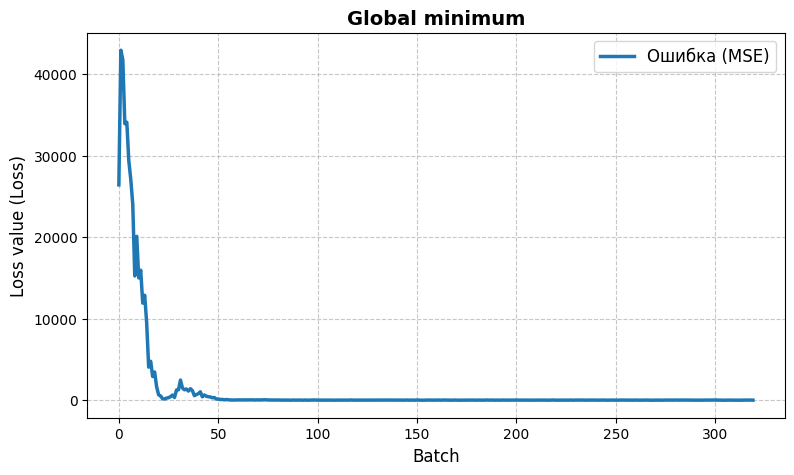

In [32]:
import matplotlib.pyplot as plt
import time


model = LinearMomentum(eta=0.01, epochs=10, batch_size=32, decay_factor=0.9)
start = time.time()
model.fit(X, y)
end = time.time()
plt.figure(figsize=(9, 5))
plt.plot(model.loss_history, color='#1f77b4', linewidth=2.5, label='Ошибка (MSE)')

plt.title('Global minimum', fontsize=14, fontweight='bold')
plt.xlabel('Batch', fontsize=12)
plt.ylabel('Loss value (Loss)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)

plt.show()

According to chart, the selected number of epochs is redundant. As we have 1000 samples and 32 samples in batch, in one epoch there are $\frac{1000}{32} = 31,25$ parameter updates per epoch. Our model converge on approximately 60 updates. **So we could set only 2 epochs**.

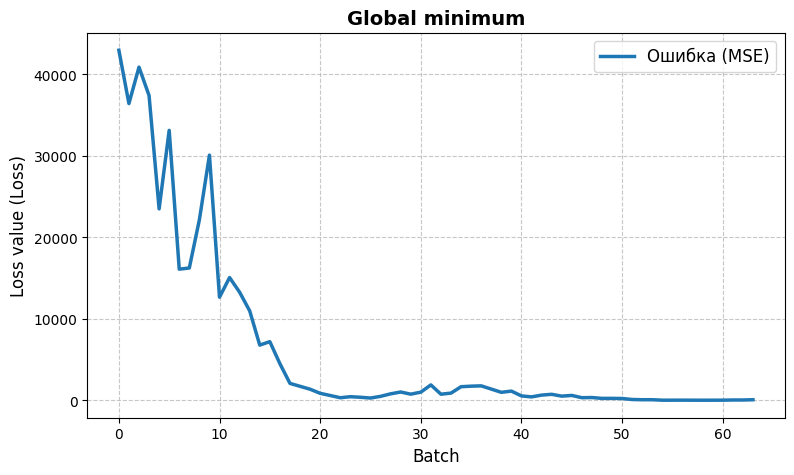

In [41]:
import matplotlib.pyplot as plt
import time


model = LinearMomentum(eta=0.01, epochs=2, batch_size=32, decay_factor=0.9)
start = time.time()
model.fit(X, y)
end = time.time()
plt.figure(figsize=(9, 5))
plt.plot(model.loss_history, color='#1f77b4', linewidth=2.5, label='Ошибка (MSE)')

plt.title('Global minimum', fontsize=14, fontweight='bold')
plt.xlabel('Batch', fontsize=12)
plt.ylabel('Loss value (Loss)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)

plt.show()

## RMSProp - Root Mean Square Propagation. Invented in 2012 by Kames Mertens and Ilya Sutskever.

It is mix of:

 - Rprop (Resilient Backpropagation). Its idea was to adjust the size of the change in each weight separately, in particular focusing on whether the gradient changes the sign.  
 - AdaGrad. 

**Main formulas:**
$$v_t = \rho v_{t-1} + (1-\rho)g_t^2$$
where:
- $v_t$ = exponential moving average squares of gradients
- $g_t = \nabla L$ - current gradient
- $\rho$ = decay factor
- $v_0 = 0$ - first value

$$\theta_t = \theta_{t-1} - g_t\frac{\eta}{\sqrt{v_t} + \varepsilon}$$

$\varepsilon$ - tiny value to avoid dividing by zero

In [33]:
random.seed(42)

class RMSProp:
    def __init__(self, eta: float = 0.001, batch_size: int = 32, rho: float = 0.9, epochs: int = 100):
        self.weights = None
        self.bias = 0.0
        self.speed_bias = 0.0
        self.speed_weights = None
        self.rho = rho
        self.epochs = epochs
        self.eta = eta
        self.batch_size = batch_size
        self.loss_history = []
        self.eps = 10**(-8)
        
    def fit(self, X, y):

        n_samples = len(X)
        n_features = len(X[0])
        
        self.weights = [0.0]*n_features
        self.bias = 0.0
        self.loss_history = []
        self.speed_bias = 0.0
        self.speed_weights = [0.0]*n_features
        
        for epoch in range(self.epochs):
            queue = list(range(n_samples))
            random.shuffle(queue)
            
            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = min(start_idx+self.batch_size, n_samples)
                batch = queue[start_idx:end_idx]
                curr_batch_size = len(batch)
                
                d_weights = [0.0]*n_features
                d_bias = 0.0
                
                error = 0
                
                grad_b = 0.0
                grad_w = [0.0] * n_features
                
                for i in batch:
                    pred = sum(X[i][j]*self.weights[j] for j in range(n_features)) + self.bias
                    
                    err = pred-y[i]
                    d_bias += err
                    for j in range(n_features):
                        d_weights[j] += err*X[i][j]
                        
                    error += err**2
                self.loss_history.append(error/curr_batch_size)
                    
                    
                grad_b = (2/curr_batch_size)*d_bias
                for j in range(n_features):
                    grad_w[j] = (2/curr_batch_size)*d_weights[j]
                
                self.speed_bias = self.rho*self.speed_bias + (1-self.rho)*(grad_b**2)
                for j in range(n_features):
                    self.speed_weights[j] = self.rho*self.speed_weights[j] + (1-self.rho)*(grad_w[j]**2)
                    
                self.bias -= (self.eta*grad_b)/((self.speed_bias)**(1/2) + self.eps)
                for j in range(n_features):
                    self.weights[j] -= (self.eta*grad_w[j])/((self.speed_weights[j])**(1/2) + self.eps)
                    
            
    def predict(self, X):
        n_features = len(X[0])
        n_samples = len(X)
        
        predictions = []
        for i in range(n_samples):
            pred = sum(X[i][j]*self.weights[j] for j in range(n_features)) + self.bias
            predictions.append(pred)
            
        return predictions
                    

In [44]:
RMSProp_model = RMSProp(eta=0.01, epochs=450, batch_size=32)


start_rms = time.time()
RMSProp_model.fit(X_train, y_train)
end_rms = time.time()
rms_time = end_rms-start_rms

rms_pred = RMSProp_model.predict(X_test)
MSE_rms = MSE(y_test, rms_pred)

print('MSE:', MSE_rms, '\n','Time:', rms_time)

MSE: 22.512219832849077 
 Time: 1.1938257217407227


**MSE: 22** in **1.2 sec** nice results. Let look to convergence chart.

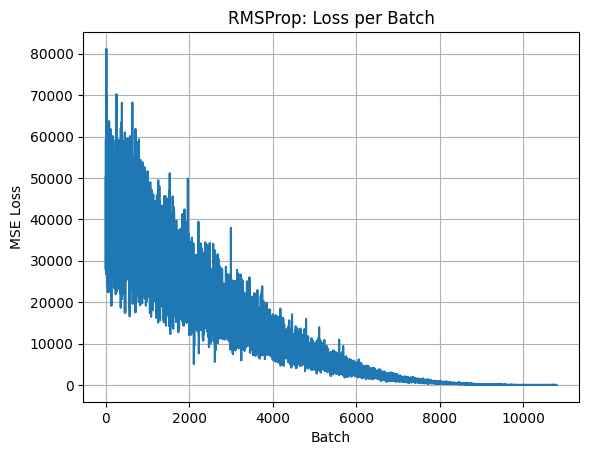

In [35]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(RMSProp_model.loss_history) + 1), RMSProp_model.loss_history)
plt.xlabel("Batch")
plt.ylabel("MSE Loss")
plt.title("RMSProp: Loss per Batch")
plt.grid(True)
plt.show()

I already chose best amount of epochs. On chart we can see great trend.

## Adam: Adaptive Moment Estimation

Adam is merging of previous two algorithms: RMSProp and Momentum.  
It uses impulse and exponential moving average squares of gradients

**Main formulas:**

$$m_t = \rho_1 m_{t-1} + (1-\rho_1)g_t, \quad \hat{g_t} = \frac{g_t}{1-\rho_1^t}$$
$$v_t = \rho_2 v_{t-1} + (1-\rho_2)g_t^2, \quad \hat{m_t} = \frac{m_t}{1-\rho_2^t}$$


$$\theta_t = \theta_{t-1} - m_t\frac{\eta}{\sqrt{v_t} + \varepsilon}$$

We have to correct $m_t$ and $g_t$ scince at the beginning of the training we set $m_0 = 0$ and $v_0=0$. Because of this, the first values of the average are artificially understated.

In [38]:
class Adam:
    def __init__(self, epoches: int = 500, batch_size: int = 16, eta: float = 0.01, rho_m: float = 0.9, rho_rms: float = 0.999, ):
        self.epoches = epoches
        self.batch_size = batch_size
        self.eta = eta
        self.rho_m = rho_m
        self.rho_rms = rho_rms
        self.weights = None
        self.bias = 0.0
        self.eps = 10**(-8)
        self.moment_b = 0.0
        self.moment_weights = None
        self.speed_b = 0.0
        self.speed_weights = None
        
    def fit(self, X, y):
        n_samples = len(X)
        n_features = len(X[0])
        
        self.weights = [.0]*n_features
        self.bias = 0.0
        self.moment_b = 0.0
        self.moment_weights = [.0]*n_features
        self.speed_b = 0.0
        self.speed_weights = [.0]*n_features
        self.loss_history = []
        
        
        t = 1
        for epoch in range(self.epoches):
            queue = list(range(n_samples))
            random.shuffle(queue)
            
            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = min(start_idx+self.batch_size, n_samples)
                batch = queue[start_idx:end_idx]
                curr_batch_size = len(batch)
                
                
                moment_b_correct = 0.0
                speed_b_correct = 0.0
                moment_weights_correct = [.0]*n_features
                speed_weights_correct = [.0]*n_features
                
                d_theta = [.0]*n_features
                d_bias = .0
                
                error = 0
                
                for i in batch:                    
                    
                    pred = sum(X[i][j]*self.weights[j] for j in range(n_features)) + self.bias
                    
                    err = pred-y[i]
                    d_bias += err
                    for j in range(n_features):
                        d_theta[j] += err*X[i][j]
                    error += err**2
                self.loss_history.append(error/curr_batch_size)
                        
                grad_bias = (2/curr_batch_size)*d_bias
                
                self.moment_b = self.rho_m*self.moment_b + (1-self.rho_m)*grad_bias
                self.speed_b = self.rho_rms*self.speed_b + (1-self.rho_rms)*(grad_bias**2)
                
                moment_b_correct = self.moment_b / (1 - (self.rho_m**t))
                speed_b_correct = self.speed_b / (1 - (self.rho_rms**t))
                
                for j in range(n_features):
                    grad_weights_j = (2/curr_batch_size)*d_theta[j]
                    
                    self.moment_weights[j] = self.rho_m*self.moment_weights[j] + (1-self.rho_m)*grad_weights_j
                    self.speed_weights[j] = self.rho_rms*self.speed_weights[j] + (1-self.rho_rms)*(grad_weights_j**2)
                    
                    moment_weights_correct[j] = self.moment_weights[j] / (1-(self.rho_m**t))
                    speed_weights_correct[j] = self.speed_weights[j] / (1-(self.rho_rms**t))
                    
                t += 1
                
                self.bias -= (self.eta*moment_b_correct)/((speed_b_correct**(1/2)) + self.eps)
                for j in range(n_features):
                    self.weights[j] -= (self.eta*moment_weights_correct[j])/((speed_weights_correct[j]**(1/2)) + self.eps)
                    
    def predict(self, X):
        predictions = []
        for i in range(len(X)):
            pred = sum(X[i][j]*self.weights[j] for j in range(len(X[0]))) + self.bias
            predictions.append(pred)
            
        return predictions    
        

In [49]:
Adam_model = Adam(epoches=300, batch_size=16, eta=0.01)
start_adam = time.time()
Adam_model.fit(X_train, y_train)
end_adam = time.time()

adam_preds = Adam_model.predict(X_test)

adam_mse = MSE(y_test, adam_preds)

print(adam_mse)
print(end_adam-start_adam)


23.89957852916214
0.8848235607147217


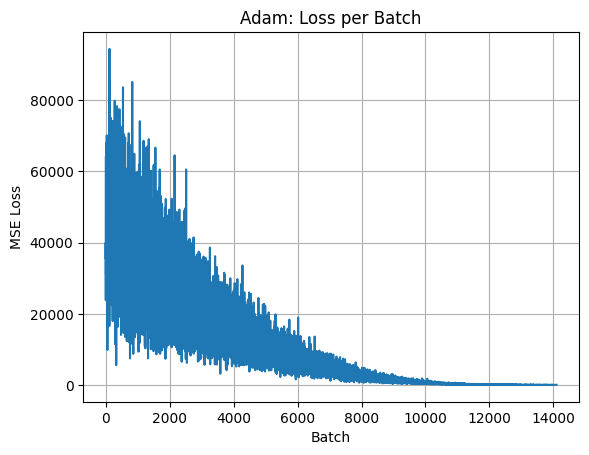

In [50]:
plt.plot(range(1, len(Adam_model.loss_history) + 1), Adam_model.loss_history)
plt.xlabel("Batch")
plt.ylabel("MSE Loss")
plt.title("Adam: Loss per Batch")
plt.grid(True)
plt.show()